# A história até aqui

Em todos os problemas formulados, o que chamamos de Kernel também é conhecido como a função de Green do problema físico em questão. Esta função é responsável por **impor as características do modelo físico** ao termo **fonte**, e o resultado é o que se **mede** (numa situação sem ruído, pelo menos). No nosso esquema de problemas inversos, dado na Figura 1, o sistema modelado pela função de Green transforma o sinal de entrada numa saída que conseguimos medir. 

<figure style="text-align: center;">
    <img src="\..\figs\probinv_conceito.png" width="500" alt="Imagem do conceito do problema inverso.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 1: Conceito do problema inverso (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 1.3).
    </figcaption>
</figure>

Esta transformação é modelada por integrais do tipo de Fredholm, uma operação também conhecida, na área de processamento de sinais, como **convolução**. 

Nos problemas inversos discretos lineares, nosso conjunto de **medições** e **modelo** serão organizados em uma equação matricial do tipo

\begin{equation}
\mathbf{A} \mathbf{x} = \mathbf{b},
\tag{1}
\end{equation}
em que $\mathbf{b} \in \mathbb{C}^{M \times 1}$ é o vetor com as **medições**, $\mathbf{A} \in \mathbb{C}^{M \times L}$ contém os kernels de convolução associados ao **modelo** matemático direto (*forward model*), e  $\mathbf{x} \in \mathbb{C}^{L \times 1}$ é o vetor solução desejado. 

Quando conhecemos $\mathbf{b}$ (com algum erro e incerteza) e $\mathbf{A}$ (potencialmente com simplificações), podemos tentar recuperar $\mathbf{x}$. Nós já vimos como isto pode ser um problema difícil em sistemas de pequenas dimensões ($2 \times 2$ ou $3 \times 2$, $1 \times 2$, etc). A solução **ingênua**, dada por $\tilde{\mathbf{x}} = \mathbf{A}^{-1}\mathbf{b}$, falha miseravelmente devido ao ruído. Imagine, então, a dificuldade com problemas de escala média e larga. Como veremos aqui, a solução **ingênua** falha até mesmo devido a erros de arredondamento.

No entanto, o problema tem solução (ou melhor, aproximação). Ao nosso resgate vêm o **SVD** (*Singular Value Decomposition* ou decomposição em valores singulares) e as técnicas de regularização. 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy
import sys
sys.path.append('..')
import regu_test_problems as tp
sys.path.append('D:/Work/dev/insitu_sim_python/insitu') # Change this path
import lcurve_functions as lc

In [2]:
def cn_scistr(cn):
    """ format cond number to scietific string
    """
    cn = np.linalg.cond(A)
    cn_sci_form = f"{cn:.2e}"
    base, exponent = cn_sci_form.split("e")
    exp_clean = int(exponent)
    return r"{} $\cdot 10^{{{}}}$".format(base, exp_clean)#f"{base} 10^{exp_clean}"

# 1. Medição da densidade (toy problem)

Vamos relembrar rapidamente a medição inversa da densidade ao longo do espaço (1D), $\rho(x)$, que origina um campo gravitacional medido $g(x')$ a uma distância $d$ da fonte. Um esquema do problema pode ser visto na Figura 2. 

<figure style="text-align: center;">
    <img src="\..\figs\gravity.png" width="500" alt="Imagem do conceito do problema problema da gravidade.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 2: Conceito da medição inversa da densidade (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 2.1).
    </figcaption>
</figure>

A equação integral de Fredholm do problema em mãos é dada por

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x
\end{equation}

com o Kernel (ou função de Green) dado por 

\begin{equation}
K(x',x) = \frac{d}{[d^2+(x' - x)^2]^{3/2}}.
\end{equation}

A dimensão física da densidade é $\rho(x)$ [kg/m] (1D). Falta a constante de gravitação universal, $G$ [Nm$^2$/kg$^2$], mas ela não fará muita falta pro nosso propósito. 

### A. Medição vs. distância

Vamos relembrar os efeitos de suavização que ocorrem na aceleração da gravidade medida $g(x)$ ao aumentarmos a distância de medição $d$ do termo-fonte.

- Quanto **mais longe** medirmos da fonte (origem do fenômeno), **menor** é a amplitude da grandeza medida (consequência).
- Aparentemente, a grandeza medida também se torna **mais suave** ou apresenta menor variação ao longo do espaço, devido ao decaimento mais abrupto das componentes de alta frequência com a distância.

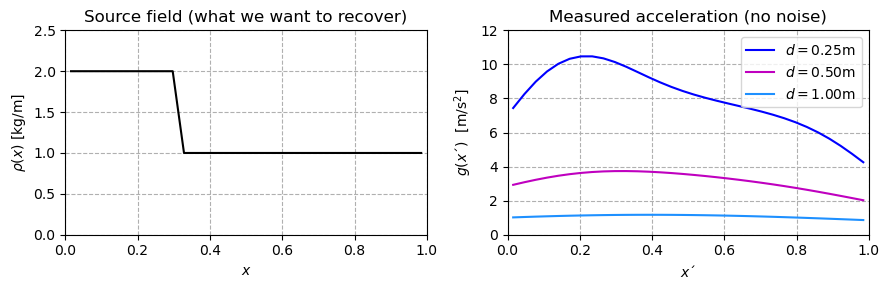

In [3]:
n = 32 # order
a = 0 # bottom limit
b = 1 # upper limit
# measured distances
distances = [0.25, 0.5, 1]
# source function
rhox = tp.density_piecewise(n = n)
# sampling measurement points
x = np.linspace(0, 1, n)
# measured gravity (fake data with no noise at all)
g_vs_d = []
for d in distances:
    A, x = tp.gravity_model(n = n,a = a,b = b,d = d) # matrix
    g_vs_d.append(A @ rhox) 
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, 'k')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((0, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (what we want to recover)')
axs[1].plot(x, g_vs_d[0], label = r'$d = 0.25$m', color = 'b')
axs[1].plot(x, g_vs_d[1], label = r'$d = 0.50$m', color = 'm')
axs[1].plot(x, g_vs_d[2], label = r'$d = 1.00$m', color = 'dodgerblue')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 12))
axs[1].legend(loc = 'upper right')
axs[1].grid(True)
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

### B. Influência da frequência espacial no dado medido

Vamos relembrar a influência da frequência do sinal do termo fonte. Vamos investigar um **termo fonte** com apenas uma frequência

\begin{equation}
\rho(x) = \text{sin}(2\pi f_{\rho} x)
\end{equation}

Os **componentes de alta frequência espacial** tendem a **decair abruptamente** a partir da fonte.

Note então que a amplitude do fenômeno medido é menor para:
- maiores distâncias (da simulação anterior)
- maiores frequências espaciais no fenômeno de origem

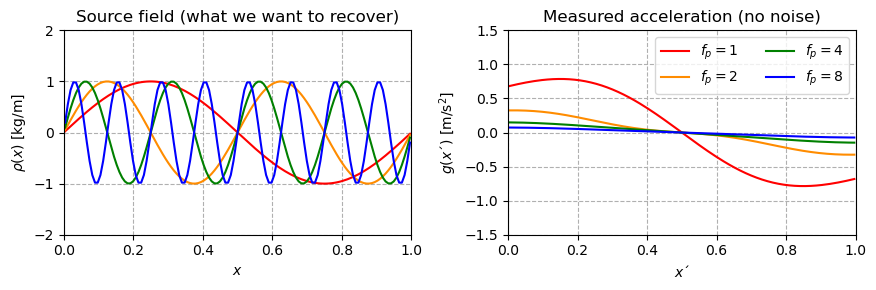

In [4]:
n = 128 # order
a = 0 # bottom limit
b = 1 # upper limit
d = 0.5

# measured coordinates
x = np.linspace(0, 1, n)

# frequencies to be investigated
fp = [1, 2, 4, 8]

# model
A,x = tp.gravity_model(n = n,a = a,b = b,d = d)

rhox_vs_fp = [] # source functions
g_vs_fp = [] # measured data as a function of fp
for p in fp:
    rhox = tp.density_sin(x, p)
    rhox_vs_fp.append(rhox)
    g_vs_fp.append(A @ rhox)
    
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox_vs_fp[0], color = 'r')
axs[0].plot(x, rhox_vs_fp[1], color = 'darkorange')
axs[0].plot(x, rhox_vs_fp[2], color = 'g')
axs[0].plot(x, rhox_vs_fp[3], color = 'b')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((-2, 2))
axs[0].grid(linestyle = '--')
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (what we want to recover)')
axs[1].plot(x, g_vs_fp[0], label = r'$f_p = 1$', color = 'r')
axs[1].plot(x, g_vs_fp[1], label = r'$f_p = 2$', color = 'darkorange')
axs[1].plot(x, g_vs_fp[2], label = r'$f_p = 4$', color = 'g')
axs[1].plot(x, g_vs_fp[3], label = r'$f_p = 8$', color = 'b')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((-1.5, 1.5))
axs[1].legend(loc = 'upper right', ncols = 2)
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$ [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

### Pergunta: num problema inverso, qual é o problema com as altas frequências?

<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Menores amplitudes são causadas por: **maiores distâncias** de medição e **maiores frequências espaciais** no fenômeno de origem.
- As amplitudes menores em $g(x^{'})$ (associadas às maiores frequências) tendem a ser **mais corrompidas por ruído**;
- Ao tentar inferir componentes de alta frequência espacial em $\rho(x)$, a partir de dados medidos em $g(x^{'})$ haverá **amplificação**.
- Se não formos cautelosos, vamos acabar amplificando ruído e condenando nossa solução.
 
</details>

# A solução ingênua

Antes de entrarmos no SVD, vejamos o que acontece com a solução **ingênua** ($\mathbf{x} = \mathbf{A}^{-1}\mathbf{b}$) num problema de média escala, mesmo quando $\mathbf{b}$ é medido perfeitamente.

Você vai ver que a solução ingênua é frequentemente inútil, especialmente quando o número de medições e incógnitas aumenta. Isto ocorre porque à medida que a ordem do problema aumenta, o número de condição de $\mathbf{A}$ se torna excessivamente grande, podendo chegar à ordem de $\text{cond}(\mathbf{A})\approx 10^{17}$ para $n=32$. Assim, mesmo os erros de arredondamento numérico fazem a solução ingênua explodir. 

**OBS:** Aqui não há ruído, mas imagine como o efeito do número de condição será pior na situação real com ruído. A análise via SVD deixará isso mais claro.

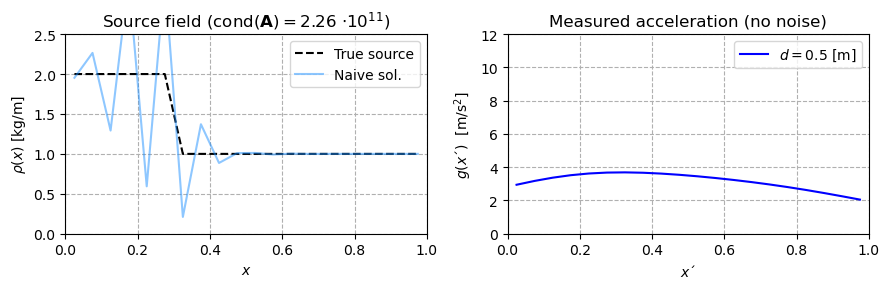

In [5]:
n = 20 # order - LET'S VARY
a = 0 # bottom limit
b = 1 # upper limit
d = 0.5 # measured distance
# source function
rhox = tp.density_piecewise(n = n)

A, x = tp.gravity_model(n = n,a = a,b = b,d = d) # matrix
g_noiseless = A @ rhox

Ainv = np.linalg.inv(A)
rhox_naive = Ainv @ g_noiseless

# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, '--k', label = "True source")
axs[0].plot(x, rhox_naive, 'dodgerblue', alpha = 0.5, label = "Naive sol.")
axs[0].legend()
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((0, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = ${})'.format(cn_scistr(np.linalg.cond(A))))
axs[1].plot(x, g_noiseless, label = r'$d = {}$ [m]'.format(d), color = 'b')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 12))
axs[1].legend(loc = 'upper right')
axs[1].grid(True)
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

# 2. SVD (Singular Value Decomposition)

A decomposição em valores singulares, ou SVD, é uma técnica fundamental da álgebra linear que decompõe (ou fatora) uma matriz **retangular** $\mathbf{A} \in \mathbb{C}^{M \times L}$ em um produto de três matrizes mais simples (**duas ortogonais e uma diagonal**). A técnica numérica e discreta do SVD é baseada em Singular Value Expansion (SVE) para funções contínuas.

O SVD tem uma conexão muito concreta com a análise de problemas inversos discretos e com as técnicas de **regularização** usadas para estabilizar o processo de encontrar ou aproximar uma solução. Esta não é a única forma de decompor uma matriz, mas, com certeza, nos ensinará muito sobre como encontrar uma solução **sensata** para um problema inverso complexo. 

Uma observação importante é que a decomposição em SVD não é **única**. Ao utilizar diferentes pacotes (numpy ou scipy) você terá resultados diferentes (ou mesmo entre diferentes linguagens de programação). No entanto, este fato tende a não ter grande impacto nos algorítmos de regularização que estudaremos.

Cabe também dizer que, em problemas inversos de dimensões muito grandes (quando $M$ ou $L$ ultrapassam os milhares), a expansão em SVD pode tornar-se computacionalmente muito custosa. Nestes casos, tentaremos obter soluções **sensatas** por métodos iterativos, que apenas usam a operação de produto interno nas linhas e colunas de $\mathbf{A}$.

## A. Então, o que é o SVD?

A expansão de uma matriz $\textbf{A} \in \mathbb{C}^{M \times L}$ ($M\geq L$) em **SVD** é dada por

\begin{equation}
\textbf{A} = \textbf{U} \Sigma \textbf{V}^H=\sum\limits_{i=1}^{L}\textbf{u}_i \sigma_i \textbf{v}_{i}^{H},
\tag{2}
\end{equation}
em que as matrizes $\textbf{U} \in \mathbb{C}^{M \times L}$ e $\textbf{V} \in \mathbb{V}^{L \times L}$ são compostas por vetores colunas chamados de: 

- left singular vectors: $\textbf{U} = [\textbf{u}_1, \textbf{u}_2, \cdots, \textbf{u}_M]$
- right singular vectors: $\textbf{V} = [\textbf{v}_1, \textbf{v}_2, \cdots, \textbf{v}_L]$

e ambas as matrizes têm colunas ortonormais: 

- $\textbf{u}_{i}^{H}\textbf{u}_{j} = \textbf{v}_{i}^{H}\textbf{v}_{j} = \delta_{ij}$, ou
- $\textbf{U}^{H}\textbf{U} = \textbf{V}^{H}\textbf{V} = \textbf{I}$. 

Já a matriz $\Sigma \in \mathbb{R}^{L \times L}$ é a matriz de valores singulares (**singular values**). Esta matriz é diagonal e os valores singulares estão organizados em ordem **decrescente**, a saber

\begin{equation}
\Sigma = \text{diag}(\sigma_1, \sigma_2, ..., \sigma_L), \ \ \ \ \ \ \ \sigma_1 \geq \sigma_2 \geq \cdots \sigma_L.
\tag{3}
\end{equation}


### Verificando as propriedades

Vamos verificar as propriedades em um problema de pequenas dimensões.

In [8]:
n = 20
a = 0
b = 1
d = 0.5
A,x = tp.gravity_model(n = n,a = a,b = b,d = d)
[U,s,V] = lc.csvd(A)

In [9]:
print("Shape of A: {}".format(A.shape))
print("Shape of U: {}".format(U.shape))
print("Shape of V: {}".format(V.shape))
print("Shape of s: {}".format(s.shape))

Shape of A: (20, 20)
Shape of U: (20, 20)
Shape of V: (20, 20)
Shape of s: (20,)


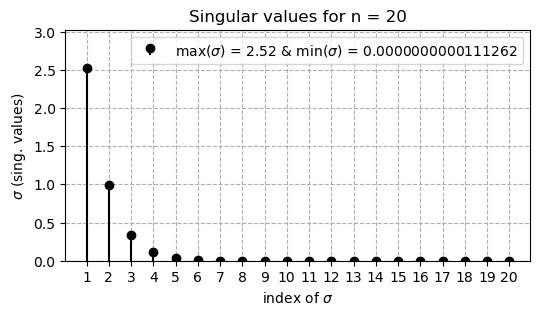

In [10]:
plt.figure(figsize = (6,3))
plt.stem(np.arange(len(s))+1, s, "k", basefmt=" ", label = r"max($\sigma$) = {:.2f} & min($\sigma$) = {:.16f}".format(s[0], s[-1]))
plt.legend()
plt.ylim((0, 1.2*np.amax(s)))
plt.title(r"Singular values for n = {}".format(n))
plt.xlabel(r'index of $\sigma$')
plt.ylabel(r'$\sigma$ (sing. values)')
plt.xticks(np.arange(len(s))+1)
plt.grid(linestyle = '--');

#### Checando ortogonalidade

In [11]:
i = 6
j = 7
print("dot prod for on U: row {}, col {}: dot = {:.16f}".format(i,j, np.dot(U[:,i], U[:,j])))
print("dot prod for on V: row {}, col {}: dot = {:.16f}".format(i,j, np.dot(V[:,i], V[:,j])))

dot prod for on U: row 6, col 7: dot = 0.0000000000000004
dot prod for on V: row 6, col 7: dot = 0.0000000000000001


## B. Pseudo inversa

O SVD pode ser usado para calcular a matriz **pseudo-inversa** (associada a solução por mínimos quadrados), da seguinte forma

\begin{equation}
\textbf{A}^{\dagger} = \textbf{V} \Sigma^{-1} \textbf{U}^H.
\tag{4}
\end{equation}

**Note:** 
- você não precisa inverter as matrizes $\textbf{U}$ e $\textbf{V}$ (já que elas são ortogonais) e o cálculo da hermitiana é trivial.
- a matriz $\Sigma^{-1}$ também tem um cálculo trivial. Seus componentes são:

\begin{equation}
\sigma_{\text{inv}} = 
\begin{cases}
1/\sigma_i, \ \ \text{se} \ \ \sigma_i \neq 0 \\ \\
0, \ \ \ \ \ \ \ \ \text{se} \ \ \sigma_i = 0 \\
\end{cases}.
\end{equation}

Logo, para uma matriz $\Sigma$ com componentes não nulos, a estrutura de $\Sigma^{-1}$ é

\begin{equation}
\Sigma^{-1} = 
\begin{bmatrix}
\sigma_{1}^{-1} & 0 & \cdots & 0 \\
0 & \sigma_{2}^{-1} & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & \sigma_{L}^{-1} \\
\end{bmatrix}.
\tag{5}
\end{equation}

ou 

\begin{equation}
\Sigma^{-1} = \text{diag}(\sigma_{1}^{-1}, \sigma_{2}^{-1}, \cdots, \sigma_{L}^{-1}).
\tag{6}
\end{equation}

### Pergunta: Conseguimos notar um problema aqui? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- se $\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_L$, temos **atenuação** no problema direto, já que $\textbf{b} = \textbf{Ax} = (\textbf{U} \Sigma \textbf{V}^H) \ \textbf{x}$;
- então $\sigma_{1}^{-1} \leq \sigma_{2}^{-1} \leq \cdots \leq \sigma_{L}^{-1}$ temos **amplificação** no problema inverso, já que $\textbf{x} = \textbf{A}^{\dagger}\textbf{b} = (\textbf{V} \Sigma^{-1} \textbf{U}^H) \ \textbf{b}$;

**Em suma:** A inversa tende à instabilidade porque seus valores singulares são cada vez menores. Se você aumenta a ordem do problema, você tem mais e mais valores singulares (com $\text{min}(\sigma) \rightarrow 0$ e $1/\text{min}(\sigma) \rightarrow \infty$)
</details>                                                                                                            

## C. Número de condição

A norma Frobenius da matriz $\textbf{A}$ pode ser expressa em termos dos valores singulares, $\sigma$, a saber

\begin{equation}
\left\|\textbf{A}\right\|_{F} = \sqrt{\sum\limits_{i=1}^{L}\sigma_{i}^{2}}.
\tag{7}
\end{equation}

Logo, o número de condição dado por $\text{cond}(\mathbf{A}) = \frac{\text{max}\left(\left\|\textbf{Ax}\right\|_{2}\right/\left\|\textbf{x}\right\|_{2})}{\text{min}\left(\left\|\textbf{Ax}\right\|_{2}\right/\left\|\textbf{x}\right\|_{2})}$ é dado por

\begin{equation}
\text{cond}(\mathbf{A}) = \sigma_1 / \sigma_L,
\tag{8}
\end{equation}
que tende a aumentar significativamente para problemas de maior escala, já que o menor valor singular será cada vez menor, levando à instabilidade da inversa.

### Vamos verificar

Note como calcular a matriz inversa via SVD já ajuda no computo da solução.

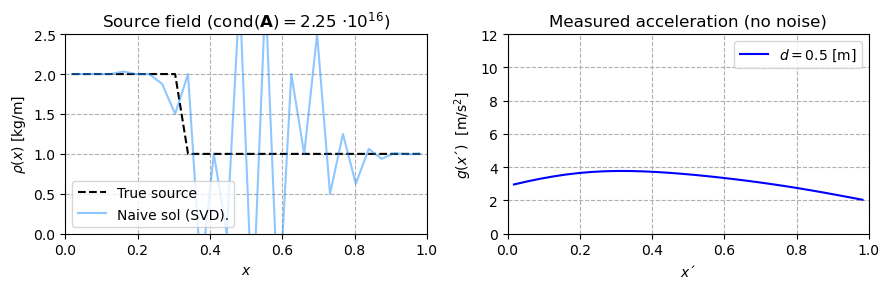

In [6]:
n = 28 # order
a = 0 # bottom limit
b = 1 # upper limit
d = 0.5 # measured distance
# source function
rhox = tp.density_piecewise(n = n)

A, x = tp.gravity_model(n = n,a = a,b = b,d = d) # matrix
g_noiseless = A @ rhox

# Pseudoinversa
[U,s,V] = lc.csvd(A)
cond_A = s[0]/s[-1]
Ainv = V @ np.diag(1/s) @ np.conj(U).T
rhox_naive = Ainv @ g_noiseless

# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, '--k', label = "True source")
axs[0].plot(x, rhox_naive, 'dodgerblue', alpha = 0.5, label = "Naive sol (SVD).")
axs[0].legend()
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((0, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = ${})'.format(cn_scistr(np.linalg.cond(A))))
axs[1].plot(x, g_noiseless, label = r'$d = {}$ [m]'.format(d), color = 'b')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 12))
axs[1].legend(loc = 'upper right')
axs[1].grid(True)
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

## D. O papel do SVD na análise do problema inverso.

Dado que $\textbf{A}^{\dagger} = \textbf{V} \Sigma^{-1} \textbf{U}^H$, podemos escrever

\begin{equation}
\textbf{x} = \textbf{A}^{\dagger}\textbf{b} = (\textbf{V} \Sigma^{-1} \textbf{U}^H) \textbf{b} =  \sum\limits_{i=1}^{L}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\tag{9}
\end{equation}

### Pergunta: O que acontece com os termos do somatório à medida que $i$ aumenta? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- como $\sigma_i$ diminui e está no denominador, cada termo do somatório tende a ser maior que o anterior (**amplificação** da solução);
- é isso que faz a solução tender à instabilidade.

### Os componentes do somatório

Vamos analisar os componentes do somatório para avaliar a saúde do problema inverso. Particularmente estamos interessados em: 

- nos vetores singulares $\mathbf{u}_i$ e $\mathbf{v}_i$ 
- nos valores singulares: $\sigma_i$
- nos valores: $|\textbf{u}_{i}^{H}\textbf{b}|$
- nos valores: $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i$

Vamos começar pelas colunas de $\mathbf{U}$ e $\mathbf{V}$ e entender sua relação com a frequência do sinal.

In [7]:
def plot_colvecs(U, maxmin = 0.3):
    """ plot the first 16 column vectors in matrix U or V
    
    Parameters: 
    -------------------
    U : ndArray
        matrix to plot
    """
    fig, axs = plt.subplots(4, 4, figsize = (9,5), sharex=True, sharey=True)
    j = 0
    for row in np.arange(4):
        for col in np.arange(4):
            axs[row,col].plot(U[:,j], 'k', alpha = 0.8, label = r"{}".format(j))
            axs[row,col].legend()
            axs[row,col].set_xlim((0,len(U[:,j])))
            axs[row,col].set_ylim((-0.2,0.2))
            j += 1
            axs[row,col].grid(linestyle = '--')
            #axs[row,col].set_xlim((-maxmin, maxmin))
            axs[row,col].set_ylim((-maxmin, maxmin))
            axs[3,col].set_xlabel(r'index')
        axs[row,0].set_ylabel(r'$u$')
    plt.tight_layout()

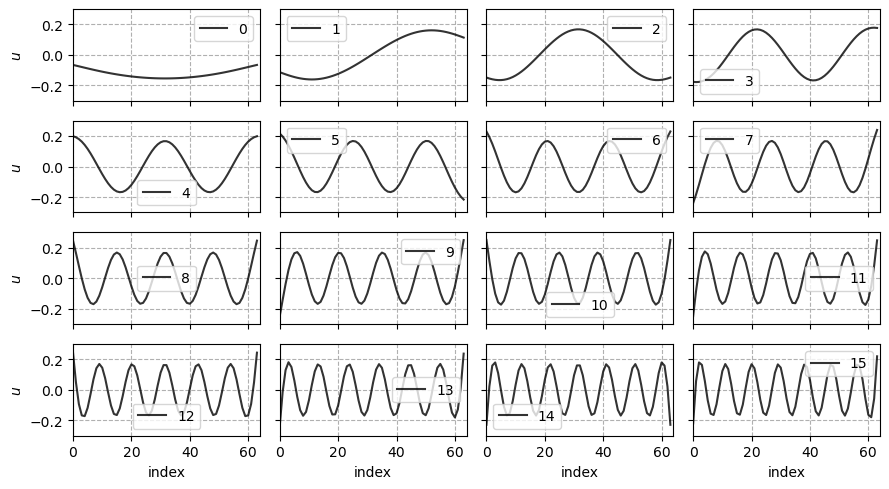

In [10]:
n = 64
a = 0
b = 1
d = 0.25
A, x = tp.gravity_model(n = n,a = a,b = b,d = d)
[U,s,V] = lc.csvd(A)
plot_colvecs(U)

### O que você nota? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- As colunas em $\textbf{U}$ formam uma base de funções **ortogonais** para construir $\textbf{x}$ [veja Eq. (9)];
- À medida que o índice da coluna aumenta, a taxa de oscilação (**frequência**) das colunas de $\textbf{U}$ também aumenta;
- Logo, as colunas em $\textbf{U}$ também formam uma base de funções **espectrais**;
- Os valores singulares de **menor valor** (maior índice) estão associados às colunas de $\textbf{U}$ de ordem **mais elevada** e, portanto, às componentes de **maior frequência**;
- E como $\sigma_i$ sempre diminui, as componentes de maior frequência tendem a ser atenuadas no problema direto.    

## O plot de Picard

O plot de Picard é uma ferramenta gráfica que permite analisar a saúde de um problema inverso. Num mesmo gráfico, plotamos

- os valores singulares: $\sigma_i$
- os valores: $|\textbf{u}_{i}^{H}\textbf{b}|$
- os valores: $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i$

e analisamos as taxas de decaimento das funções. 

Vamos pensar primeiro no caso: uma medição **sem ruído**.

In [18]:
def plot_picard(U,s,b):
    """ Execute Picard plot
    
    Parameters: 
    -------------------
    U : ndArray
        left matrix U of SVD of size M x L
    s : 1dArray
        Singular values of SVD of size M x 1
    b : measured data of size  M x 1.
    """
    cond_number = s[0]/s[-1]
    beta = np.abs(U.T @ b)
    plt.figure(figsize = (6,3))
    plt.semilogy(np.abs(s), '+k', label = r'$\sigma$')
    plt.semilogy(beta, 'xr', label = r'$|U^T b|$')
    plt.semilogy(beta/s, '.b', label = r'$|U^T b|/\sigma$')
    plt.semilogy(np.finfo(float).eps*s[0]*np.ones(len(s)), '--', linewidth = 2, color = 'Grey', label = r'eps$\cdot \sigma_1$')    
    plt.legend(loc = 'lower left')
    plt.ylim((0.1*s[-1], 100*s[0]))
    plt.xlabel(r'$i$')
    plt.ylabel(r'$\sigma_i$, $|U^Tb|$, $|U^Tb|/\sigma_i$')
    plt.title('cond(A) = {}'.format(cond_number), loc='right')
    plt.grid(linestyle = '--')

Approx machine precision: 2.220446049250313e-16
eps x maximum singular value: 1.4342961507025177e-15
52th singular value: 1.871619338477493e-15


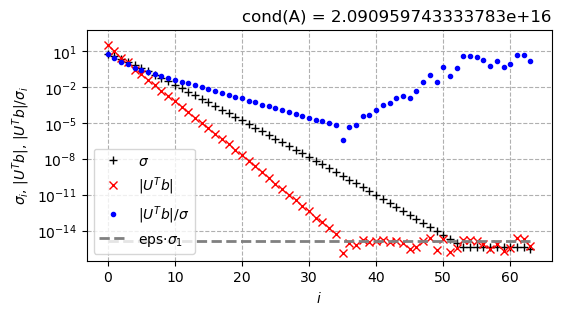

In [13]:
print("Approx machine precision: {}".format(np.finfo(np.float64).eps))
print(r"eps x maximum singular value: {}".format(np.finfo(np.float64).eps * s[0]))
print(r"52th singular value: {}".format(s[51]))
rhox = tp.density_sin(x, 0.5) + 0.5* tp.density_sin(x, 1.0)
#rhox = tp.density_piecewise(n = n)
gxl = A @ rhox
plot_picard(U,s,gxl)
#plt.savefig("picardplot.png")

### O que você nota sobre os valores singulares (em preto)? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  Os **valores singulares** decaem rapidamente;
-  Para $i \geq 51$, tendem a estabilizar-se próximos ao *eps* da máquina. Isso se deve à influência da aritmética de **precisão finita**;
-  Estes pequenos valores singulares são, de fato, menores do que a precisão da máquina $\text{eps} \times \sigma_1$, e **não são confiáveis** para a inversão da matriz;
-  O $\text{cond}(\textbf{A}) \approx 10^{16}$, o que, para todos os efeitos práticos, é infinito

### O que você nota sobre $|\textbf{u}_{i}^{H}b|$ (em <span style="color:red"> vermelho</span>) e $|\textbf{u}_{i}^{H}b|/\sigma_i$ (em <span style="color:blue"> azul</span>)? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  Os coeficientes <span style="color:red"> *$|\textbf{u}_{i}^{H}b|$*</span>  decaem mais rapidamente do que os valores singulares, até se estabilizarem para $i \leq 35$ num patamar determinado pela precisão da máquina;
-  Os coeficientes da solução <span style="color:blue"> *$|\textbf{u}_{i}^{T}b|/\sigma_i$*</span> também decaem (para $i \leq 35$);
-  Para $i \geq 35$, os coeficientes <span style="color:blue"> *$|\textbf{u}_{i}^{T}b|/\sigma_i$*</span> começam a aumentar novamente devido aos valores imprecisos de <span style="color:red"> *$|\textbf{u}_{i}^{T}b|$*</span>
-  E novamente, são estes coeficientes ($i > 35$) que farão a solução ingênua ficar instável.

## A história até aqui

Mesmo **sem ruído** nos dados (o que nunca é a realidade na prática), não podemos esperar que a solução **ingênua** seja uma solução **sensata** para o problema inverso discreto. A influência dos erros de precisão numérica finita é suficiente para tornar a solução **ingênua** completamente inútil. Nós não observamos isso para problemas de pequenas dimensões porque o menor valor singular não será tão pequeno. Mas para qualquer problema de interesse prático, com 2 ou 3 dezenas de medições e incógnitas, a solução **ingênua** falhará mesmo que não tenhamos ruído. 

## E quando houver ruído?

Consideremos agora o caso em que:

\begin{equation}
\textbf{b} = \textbf{A x} + \textbf{n},
\end{equation}
em que $\textbf{n}$ represente um ruído aleatório gaussiano do tipo

\begin{equation}
\textbf{n} = \mathcal{N}(0, \eta^2),
\end{equation}
com média zero e desvio padrão $\eta$. Note que $\eta^2$ está relacionado ao valor RMS$^2$ (potência média do ruído).

SNR = -40.63 [dB]$


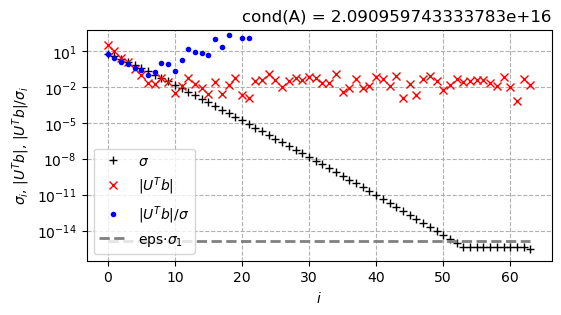

In [22]:
eta = 0.04
n = np.random.normal(loc = 0.0, scale = eta, size = len(gxl))
gxln = gxl + n
print(r"SNR = {0:.2f} [dB]$".format(20*np.log10(np.linalg.norm(n)/np.linalg.norm(gxl))))
plot_picard(U,s,gxln)

### O que você nota sobre $|\textbf{u}_{i}^{H}b|$ (em <span style="color:red"> vermelho</span>) e $|\textbf{u}_{i}^{H}b|/\sigma_i$ (em <span style="color:blue"> azul</span>)? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  Os coeficientes <span style="color:red"> *$|\textbf{u}_{i}^{H}b|$*</span>  decaem (um pouco mais rapidamente do que os valores singulares), até se estabilizarem num patamar determinado pelo **ruído**;
-  Os coeficientes da solução <span style="color:blue"> *$|\textbf{u}_{i}^{H}b|/\sigma_i$*</span> também diminuem inicialmente
-  Para valores maiores do índice $i$, <span style="color:blue"> *$|\textbf{u}_{i}^{H}b|/\sigma_i$*</span> começa a aumentar novamente.
-  As soluções calculadas são completamente **dominadas** pelos menores valores singulares  (ou de alta frequência);

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
$\mathbf{insight: }$ Os valores $\textbf{u}_{i}^{H}\textbf{b}$ correspondem a um produto interno ($\textbf{b}$ projetado sobre as diversas colunas de $\textbf{u}_{i}^{H}$). Ora, se o produto interno mede o tamanho da projeção e, à medida que $i$ aumenta, as colunas de $\textbf{u}_{i}^{H}$ modelam um sinal com maior frequência, então a ideia por trás de $\textbf{u}_{i}^{H}\textbf{b}$ é medir a projeção do sinal medido nas diversas colunas de menor e maior frequência de $\textbf{u}_{i}^{H}$. O SVD age como uma transformada de Fourier, e podemos avaliar a partir de que índice $\textbf{u}_{i}^{H}\textbf{b}$ se estabiliza (é uma análise de saúde do problema inverso).
</div>

## E. A condição discreta de Picard

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
Seja $\tau$ o $\textbf{nível}$ a partir do qual os valores singulares,  $\sigma_i$, computados tornam-se constantes devido a erros de arredondamento. A condição discreta de Picard é satisfeita se, para todos os valores singulares maiores do que $\tau$, os coeficientes correspondentes $|\textbf{u}_{i}^{T}b|$ decaem, em média, mais rapidamente do que os $\sigma_i$.
</div>


## A história até aqui

Considere que nós sempre medimos $\textbf{b}$ com algum **ruído** ou **incerteza**, de modo que:

\begin{equation}
\textbf{b} =\textbf{b}_{\text{exact}} + \textbf{n}  
\end{equation}

Em resumo, existem dois tipos diferentes de coeficientes do lado direito de $\textbf{Ax} = \textbf{b}$:

- Há coeficientes confiáveis, caracterizados por $|\textbf{u}_{i}^{T}b| > \eta$, que contêm principalmente informação sobre os dados exatos, $\textbf{b}_{\text{exact}}$. Devido à condição discreta de Picard, estes coeficientes correspondem aos **maiores** valores singulares, $\sigma_i$.

- Existem componentes "ruidosos" do SVD, aqueles para os quais $|\textbf{u}_{i}^{T}\textbf{b}_{\text{exact}}| < \eta$ e para os quais $|\textbf{u}_{i}^{T}b| \approx \eta$. Estes coeficientes correspondem aos menores valores singulares, devido também à condição discreta de Picard.

### O que podemos fazer se a solução ingênua não funciona? O que seria uma solução sensata? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
-  Nós podemos **filtrar** (de alguma forma) os valores singulares contaminados por ruído (os de menor valor).
-  Isto é o que uma técnica de **regularização** faz.
-  Que tal se tentarmos uma simples truncamento?

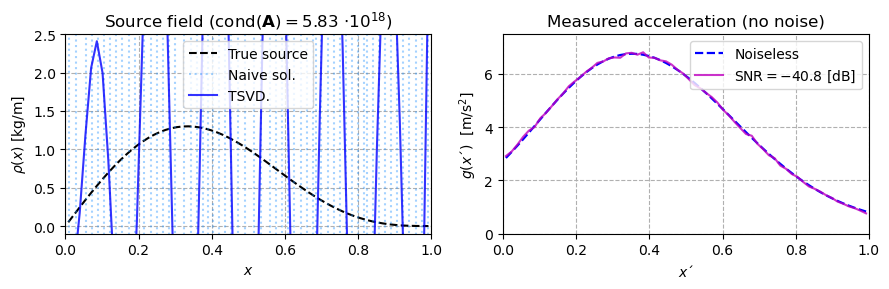

In [23]:
n = 64 # order
a = 0 # bottom limit
b = 1 # upper limit
d = 0.25 # measured distance

A, x = tp.gravity_model(n = n,a = a,b = b,d = d) # matrix
# source function
#rhox = tp.density_piecewise(n = n)
rhox = tp.density_sin(x, 0.5) + 0.5* tp.density_sin(x, 1.0)

g_noiseless = A @ rhox
# Add Noise
eta = 0.04
np.random.seed(0)
n = np.random.normal(loc = 0.0, scale = eta, size = len(g_noiseless))
g_noise = g_noiseless + n
snr = 20*np.log10(np.linalg.norm(n)/np.linalg.norm(g_noiseless))

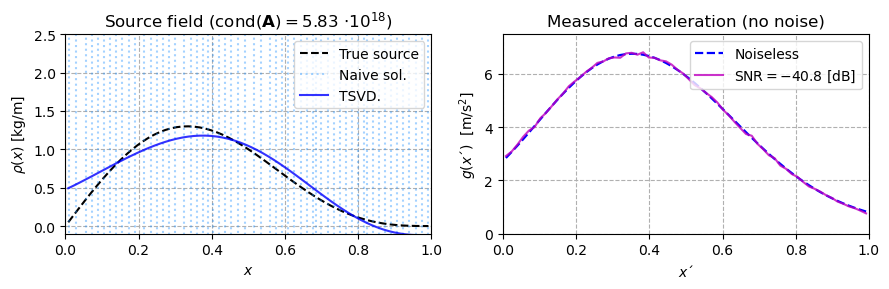

In [28]:
# Pseudoinversa (Naive)
[U,s,V] = lc.csvd(A)
cond_A = s[0]/s[-1]
Ainv = V @ np.diag(1/s) @ np.conj(U).T
rhox_naive = Ainv @ g_noise

# Pseudoinversa (Truncada)
imax = 3
AinvT = V[:,:imax] @ np.diag(1/s[:imax]) @ np.conj(U[:,:imax]).T
rhox_T = AinvT @ g_noise

# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, '--k', label = "True source")
axs[0].plot(x, rhox_naive, 'dodgerblue', linestyle = ':', alpha = 0.4, label = "Naive sol.")
axs[0].plot(x, rhox_T, 'b', alpha = 0.8, label = "TSVD.")
axs[0].legend()
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((-0.1, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = ${})'.format(cn_scistr(np.linalg.cond(A))))
axs[1].plot(x, g_noiseless, label = r'Noiseless'.format(d), color = 'b', linestyle = '--', linewidth = 1.6)
axs[1].plot(x, g_noise, label = r'SNR$ = {:.1f}$ [dB]'.format(snr), color = 'm', linestyle = '-', alpha = 0.8)
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 1.1*g_noise.max()))
axs[1].legend(loc = 'upper right')
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

# F. Adendo: sistemas sobre-determinados e sub-determinados

Aqui podemos fazer um pequeno adendo. Para a matriz  $\mathbf{A} \in \mathbb{C}^{M \times L}$, temos que

\begin{equation}
\text{rank}(\mathbf{A}) \leq \text{min}(M,L)
\end{equation}

Isso significa que o número de valores singulares não nulos é $\leq \text{min}(M,L)$. Tecnicamente, definir se um problema é **superdeterminado** (*overdetermined*) ou **subdeterminado** (*underdetermined*) vai depender do rank de  $\mathbf{A}$, já que a matriz  $\mathbf{A}$ pode ter colunas linearmente dependentes. No entanto, o que em geral tende a ocorrer na prática é

1. Se $M \geq L$ - temos mais medições do que incógnitas e, geralmente, um sistema de equações **superdeterminado** (*overdetermined*).

ou
   
2. Se $M < L$ - temos mais incógnitas do que medições e, geralmente, um sistema de equações **subdeterminado** (*underdetermined*).

Vamos pensar no SVD para os dois casos:

1. $\mathbf{A} \in \mathbb{C}^{10 \times 5}$ (*overdetermined*):

\begin{equation}
\underbrace{\textbf{A}}_{10 \times 5} = \underbrace{\textbf{U}}_{10 \times 5}  \ \underbrace{\Sigma}_{5 \times 5}  \ \underbrace{\textbf{V}^H}_{5 \times 5}
\end{equation}

2. $\mathbf{A} \in \mathbb{C}^{5 \times 10}$ (*underdetermined*):

\begin{equation}
\underbrace{\textbf{A}}_{5 \times 10} = \underbrace{\textbf{U}}_{5 \times 5}  \ \underbrace{\Sigma}_{5 \times 5}  \ \underbrace{\textbf{V}^H}_{5 \times 10}
\end{equation} 

O que se pode notar é que as dimensões de $\mathbf{U}$ e $\mathbf{V}$ mudam se $M \geq L$ ou $M<L$. O problema neste caso é que muitas das rotinas a serem usadas na regularização de problemas inversos necessitarão de lidar com essas condições de alguma forma. Mas há uma alternativa. No caso subdeterminado ($M<L$), podemos calcular a expansão em SVD de $\mathbf{A}^H \in \mathbb{C}^{L \times M}$. Neste caso, no início do problema é como se transformássemos o problema subdeterminado em superdeterminado. Pra manter a consistência, trocamos $\textbf{U}$ e $\textbf{V}$ de posição no computo do SVD. Teremos

\begin{equation}
\underbrace{\textbf{A}^H}_{10 \times 5} = \underbrace{\textbf{V}}_{10 \times 5}  \ \underbrace{\Sigma}_{5 \times 5}  \ \underbrace{\textbf{U}^H}_{5 \times 5}
\end{equation} 

Se você olhar com cuidado os códigos implementados no livro *Discrete Inverse Problems Insight and Algorithms*, e nas rotinas ligadas à disciplina, notará que é exatamente isto que é computado. 

```python
def csvd(A):
    
    """ Computes the SVD based on the size of A.

    Parameters
    ----------
        A : numpy ndarray
            sensing matrix (Nm x Nu). Nm are the number of measurements
            and Nu the number of unknowns
    Returns
    -------
        u : numpy ndarray
            left singular vectors
        sig : numpy 1darray
            singular values
        v : numpy ndarray
            right singular vectors
    """
    Nm, Nu = A.shape
    if Nm >= Nu: # more measurements than unknowns
        u, sig, v = np.linalg.svd(A, full_matrices=False)
        v = np.conjugate(v.T)
    else:
        v, sig, u = np.linalg.svd(np.conjugate(A.T), full_matrices=False)
        u = np.conjugate(u.T)
    return u, sig, v
```



# Exercícios

### 1. Inv(A) vs. pseudo-inversa
Para o exemplo do problema da gravidade dado neste capítulo, compare a solução ingênua via computação direta da inversa e da pseudo-inversa computada via SVD.

### 2. O problema da gravidade
Faça as análises de SVD, pseudo-inversa, plot de Picard e solução ingênua para o problema da gravidade variando: (a) o nível de ruído; (b) usando o termo-fonte "density_pieciwise" (o termo com descontinuidade). Compare "density_piecewise" e "density_sin" quanto à presença de componentes de alta frequência no sinal do termo-fonte. Escreva o que você observa.

### 3. O problema do calor na barra
Refaça as análises deste capítulo para o problema do calor na barra, considerando diferentes termos-fonte.

### 4. Adicionando ruído Gaussiano

A relação sinal-ruído (SNR) entre dois vetores é usualmente dada em [dB] (decibel). 

\begin{equation}
\text{SNR} = 10\text{log}_{10}\left(\frac{\left\|\mathbf{n}\right\|_{2}^{2}}{\left\|\mathbf{b}\right\|_{2}^{2}}\right),
\end{equation}
em que $\mathbf{n}$ é o vetor associado ao ruído e $\mathbf{b}$ o vetor associado aos dados medidos.

A tarefa é: dado um vetor de medições $\mathbf{b}$ e uma SNR desejada (*e.g.* -30 [dB]), calcule o vetor  $\mathbf{n}$ e plote o sinal sem e com  ruído. Para gerar $\mathbf{n}$, você pode fazer os seguintes passos:

- Gere um vetor aleatório com distribuição Normal possuindo média nula e desvio padrão 1.0 (np.random.normal(loc = 0, scale = 1, size = len(b)))
- Normalize o vetor de ruído gerado (noise/np.linalg.norm(noise))
- Compute a norma $\left\|\mathbf{b}\right\|_{2}^{2}$ usando np.linalg.norm(b);
- Compute a SNR em escala linear (snr_lin) usando a equação acima;
- Coloque o ruído na escala correta fazendo n = n*snr_lin
- Recalcule a SNR em dB (10*np.log10(np.linalg.norm(n)/np.linalg.norm(b))) e confirme se está de acordo com o prescrito.